## 1. Introduction

The aim of this project is to develop a computer vision system that can predict a person's sex and BMI (Body Mass Index) using X-ray images of the spine and surrounding areas. This type of system can be useful in healthcare and medical research. Getting information automatically from medical images can reduce the workload of specialists and make the analysis process faster. People may need a long time to examine many images, but computer systems can process them more quickly. In addition, these systems can be used as support tools in research and medical studies.

Computer vision is a suitable method for this problem because traditional machine learning methods usually need manually selected features. It can be difficult to manually identify important structures and features in X-ray images. Computer vision models can learn important features directly from the images. These models can automatically find patterns, relationships, and useful information in the data. Deep learning models can also handle complex image data effectively. For these reasons, computer vision is a suitable and powerful approach for image-based medical problems.


## Setup and Environment

In this section, the required Python libraries are imported and the notebook environment is prepared.  
The coursework requires all models to be implemented using the PyTorch ecosystem.

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

import torchvision
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

In [ ]:
SEED = 43

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [ ]:
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
CUDA available: True
GPU: Tesla T4


## Dataset Download and Loading

In this section, the Kaggle competition dataset is downloaded using the Kaggle API.  
After downloading, the dataset is extracted and the training labels, sample submission file, train images, and test images are loaded.

In [ ]:
from google.colab import userdata

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")


In [ ]:
!kaggle competitions download -c bucv26 --force
!unzip -o "*.zip"

100% 36.8M/36.8M [00:00<00:00, 103MB/s]

Archive:  bucv26.zip
  inflating: sample_submission.csv   
  inflating: test_images/1144_7090.jpg  
  inflating: test_images/1148_7947.jpg  
  inflating: test_images/1290_2619.jpg  
  inflating: test_images/1301_4384.jpg  
  inflating: test_images/1334_1570.jpg  
  inflating: test_images/1455_3146.jpg  
  inflating: test_images/1513_1725.jpg  
  inflating: test_images/1590_4958.jpg  
  inflating: test_images/1597_3761.jpg  
  inflating: test_images/1651_2690.jpg  
  inflating: test_images/1733_5951.jpg  
  inflating: test_images/1750_4226.jpg  
  inflating: test_images/1758_4712.jpg  
  inflating: test_images/1998_7549.jpg  
  inflating: test_images/1999_9904.jpg  
  inflating: test_images/2049_8804.jpg  
  inflating: test_images/2084_9094.jpg  
  inflating: test_images/2092_7682.jpg  
  inflating: test_images/2143_5607.jpg  
  inflating: test_images/2169_7528.jpg  
  inflating: test_images/2171_1150.jpg  
  inflating: test_images/2193_5298.jpg 

In [ ]:
!ls /content

bucv26.zip   sample_submission.csv  train_images
sample_data  test_images	    train_labels.csv


In [ ]:
DATA_DIR = "/content"

train_csv_path = f"{DATA_DIR}/train_labels.csv"
sample_submission_path = f"{DATA_DIR}/sample_submission.csv"

train_images_dir = f"{DATA_DIR}/train_images"
test_images_dir = f"{DATA_DIR}/test_images"

In [ ]:
train_df = pd.read_csv(train_csv_path)
sample_submission = pd.read_csv(sample_submission_path)

train_df.head()

,anon_id,sex,bmi,filename
0,5956,0,21.7,5956_8270.jpg
1,5956,0,21.7,5956_1860.jpg
2,5956,0,21.7,5956_6390.jpg
3,5956,0,21.7,5956_6191.jpg
4,5956,0,21.7,5956_6734.jpg


In [ ]:
sample_submission.head()

,filename,sex,bmi
0,1144_7090.jpg,0,23.9
1,1148_7947.jpg,0,23.9
2,1290_2619.jpg,0,23.9
3,1301_4384.jpg,0,23.9
4,1334_1570.jpg,0,23.9


In [ ]:
print("Training table shape:", train_df.shape)
print("Sample submission shape:", sample_submission.shape)

print("Number of train images:", len(os.listdir(train_images_dir)))
print("Number of test images:", len(os.listdir(test_images_dir)))

Training table shape: (1000, 4)
Sample submission shape: (195, 3)
Number of train images: 1000
Number of test images: 195


In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anon_id   1000 non-null   int64  
 1   sex       1000 non-null   int64  
 2   bmi       1000 non-null   float64
 3   filename  1000 non-null   object 
dtypes: float64(1), int64(2), object(1)
memory usage: 31.4+ KB


In [ ]:
train_df.describe()

,anon_id,sex,bmi
count,1000.000000,1000.000000,1000.00000
mean,5378.360000,0.390000,23.19600
std,2714.986243,0.487994,4.62114
min,1080.000000,0.000000,0.00000
25%,2727.500000,0.000000,21.97500
50%,5355.000000,0.000000,23.80000
75%,7691.250000,1.000000,26.00000
max,9966.000000,1.000000,31.80000


## 2. Exploratory Data Analysis (EDA) and Preprocessing:

The dataset was first loaded and explored to understand its main characteristics before training the models. Several properties of the dataset were investigated, including image dimensions, colour channels, sex distribution, and BMI distribution. Sample X-ray images were also visualised to better understand the structure and appearance of the data. During this process, possible issues such as class imbalance, unusual BMI values, or inconsistent image properties were examined because these factors can affect model performance.

The dataset was also checked for possible ethical concerns and bias. Differences in the number of samples between sex groups may create imbalance and can influence how the model learns. If one group contains more samples than another, the model may perform better for that group. Understanding these issues is important because medical prediction systems should be fair and reliable for different groups of people.

Several preprocessing steps were applied before model training. Images were resized to 224 Ãƒâ€” 224 pixels to create a consistent input size for the models. Images were converted into tensors and normalisation was applied to make training more stable. Data augmentation techniques such as rotation and horizontal flipping were also applied in some experiments. These techniques increase variation in the training data and help reduce overfitting. As a result, the model can learn more general patterns and perform better on unseen data.


In [ ]:
train_df["sex"].value_counts()

,count
sex,
0,610
1,390


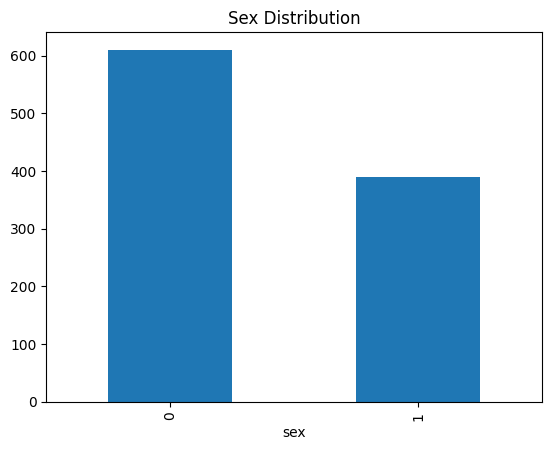

In [ ]:
train_df["sex"].value_counts().plot(kind="bar")
plt.title("Sex Distribution")
plt.show()

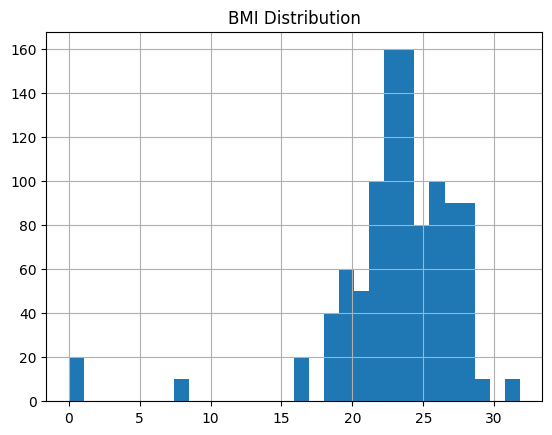

In [ ]:
train_df["bmi"].hist(bins=30)
plt.title("BMI Distribution")
plt.show()

In [ ]:
train_df.head()

,anon_id,sex,bmi,filename
0,5956,0,21.7,5956_8270.jpg
1,5956,0,21.7,5956_1860.jpg
2,5956,0,21.7,5956_6390.jpg
3,5956,0,21.7,5956_6191.jpg
4,5956,0,21.7,5956_6734.jpg


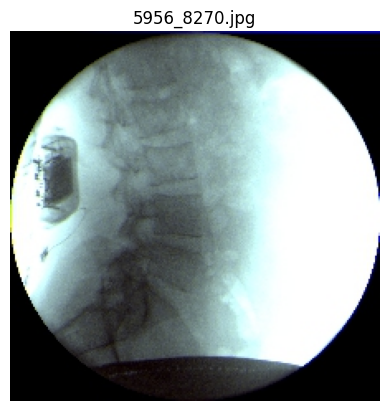

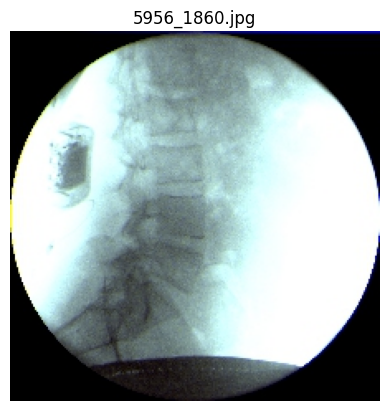

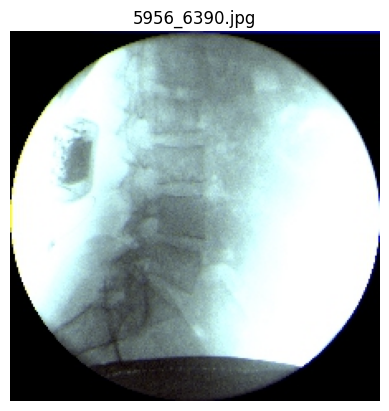

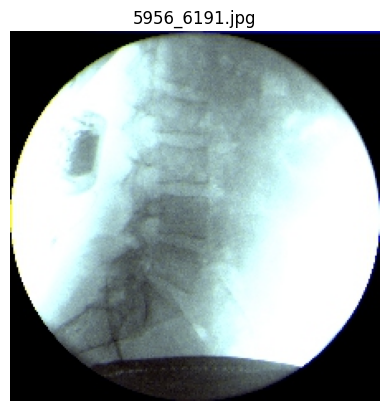

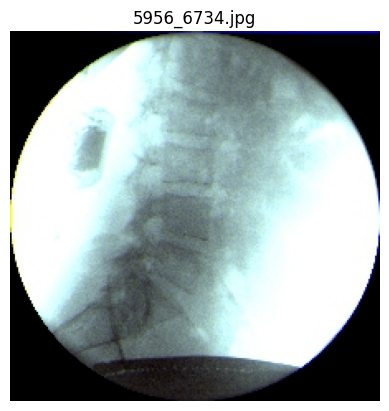

In [ ]:
sample_files = train_df["filename"].values[:5]

for file_name in sample_files:
    img_path = os.path.join(train_images_dir, file_name)
    img = Image.open(img_path)

    plt.imshow(img, cmap="gray")
    plt.title(file_name)
    plt.axis("off")
    plt.show()

In [ ]:
sample_file = train_df["filename"].iloc[0]

img_path = os.path.join(train_images_dir, sample_file)

if os.path.exists(img_path):
    img = Image.open(img_path)
    print("Image size:", img.size)
else:
    print("File not found:", img_path)

Image size: (224, 224)


In [ ]:
img = np.array(img)
print("Image shape:", img.shape)

Image shape: (224, 224, 3)


### Observations

- The dataset contains both male and female samples.
- BMI values follow a continuous distribution.
- Images are represented as RGB tensors with shape (224,224,3).
- Sample images indicate that anatomical structures are visible and may contain useful information for prediction.
- Images have consistent dimensions, which simplifies preprocessing.

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
class XrayDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None, bmi_mean=None, bmi_std=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform
        self.bmi_mean = bmi_mean
        self.bmi_std = bmi_std

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        image_path = os.path.join(self.image_dir, row["filename"])
        image = Image.open(image_path).convert("RGB")

        sex = torch.tensor(row["sex"], dtype=torch.long)

        bmi = (row["bmi"] - self.bmi_mean) / self.bmi_std
        bmi = torch.tensor(bmi, dtype=torch.float32)

        if self.transform:
            image = self.transform(image)

        return image, sex, bmi

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

groups = train_df["anon_id"]

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=SEED
)

train_idx, val_idx = next(gss.split(train_df, groups=groups))

train_data = train_df.iloc[train_idx].reset_index(drop=True)
val_data = train_df.iloc[val_idx].reset_index(drop=True)

bmi_mean = train_data["bmi"].mean()
bmi_std = train_data["bmi"].std()

print("BMI mean:", bmi_mean)
print("BMI std:", bmi_std)

BMI mean: 23.1125
BMI std: 4.284628490502652


In [ ]:
train_dataset = XrayDataset(
    train_data,
    train_images_dir,
    transform=train_transform,
    bmi_mean=bmi_mean,
    bmi_std=bmi_std
)

val_dataset = XrayDataset(
    val_data,
    train_images_dir,
    transform=val_transform,
    bmi_mean=bmi_mean,
    bmi_std=bmi_std
)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [ ]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
images, sex_labels, bmi_labels = next(iter(train_loader))

print("Image shape:", images.shape)
print("Sex shape:", sex_labels.shape)
print("BMI shape:", bmi_labels.shape)

Image shape: torch.Size([32, 3, 224, 224])
Sex shape: torch.Size([32])
BMI shape: torch.Size([32])


## 3. Baseline Model (From Scratch)

The first model used in this project was a simple baseline model created completely from scratch using PyTorch. This model was built without using any pre-trained weights because the purpose of the baseline model was to create a starting point for comparison. A simple CNN structure was used with convolution layers, activation functions, pooling layers, and fully connected layers. These layers help the model learn useful information and patterns from the X-ray images. The model structure was kept simple because the main goal at this stage was to see how well a basic model could perform before using more advanced methods.

The baseline model was trained using the training dataset and then tested on the validation dataset. During training, the model learned relationships between image features and target values. Since this project includes both sex prediction and BMI prediction, two different measurements were used to evaluate the model. Validation accuracy was used to measure how well the model predicted sex labels, while BMI loss was used to measure how close the predicted BMI values were to the real BMI values. These results were recorded and used as the first benchmark score.

The baseline model is an important part of the project because it provides a reference point for all later experiments. Without a starting model, it would be difficult to understand whether future changes improve performance or not. After getting the baseline results, different methods such as data augmentation, regularisation, different optimisation methods, and transfer learning models were tested. The results of these experiments were compared with the baseline model to see which changes improved the final performance.


In [ ]:
class BaselineCNN(nn.Module):
    def __init__(self):
        super(BaselineCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.flatten = nn.Flatten()

        self.shared_fc = nn.Sequential(
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU()
        )

        self.sex_head = nn.Linear(128, 2)   # classification
        self.bmi_head = nn.Linear(128, 1)   # regression

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.shared_fc(x)

        sex_out = self.sex_head(x)
        bmi_out = self.bmi_head(x)

        return sex_out, bmi_out

In [ ]:
model = BaselineCNN().to(device)
model

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (shared_fc): Sequential(
    (0): Linear(in_features=50176, out_features=128, bias=True)
    (1): ReLU()
  )
  (sex_head): Linear(in_features=128, out_features=2, bias=True)
  (bmi_head): Linear(in_features=128, out_features=1, bias=True)
)

In [ ]:
criterion_sex = nn.CrossEntropyLoss()
criterion_bmi = nn.SmoothL1Loss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for images, sex_labels, bmi_labels in train_loader:
        images = images.to(device)
        sex_labels = sex_labels.to(device)
        bmi_labels = bmi_labels.to(device)

        optimizer.zero_grad()

        sex_pred, bmi_pred = model(images)

        loss_sex = criterion_sex(sex_pred, sex_labels)
        loss_bmi = criterion_bmi(bmi_pred.squeeze(), bmi_labels)

        loss = loss_sex + loss_bmi
        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")

Epoch 1, Loss: 30.2194
Epoch 2, Loss: 19.5373
Epoch 3, Loss: 16.0534
Epoch 4, Loss: 12.7001
Epoch 5, Loss: 10.0707


In [ ]:
model.eval()

all_preds = []
all_labels = []
bmi_losses = []

with torch.no_grad():
    for images, sex_labels, bmi_labels in val_loader:
        images = images.to(device)
        sex_labels = sex_labels.to(device)
        bmi_labels = bmi_labels.to(device)

        sex_pred, bmi_pred = model(images)

        preds = torch.argmax(sex_pred, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(sex_labels.cpu().numpy())

        loss_bmi = criterion_bmi(bmi_pred.squeeze(), bmi_labels)
        bmi_losses.append(loss_bmi.item())

accuracy = accuracy_score(all_labels, all_preds)
avg_bmi_loss = np.mean(bmi_losses)

print("Validation Accuracy (sex):", accuracy)
print("Validation BMI Loss:", avg_bmi_loss)

Validation Accuracy (sex): 0.82
Validation BMI Loss: 0.37974583570446285


### Baseline Model Results

The baseline model achieved a validation accuracy of 0.82 for sex prediction and a BMI loss of 0.3797.

The results show that the model was able to learn useful patterns from the X-ray images. The model performed reasonably well for sex prediction, but there is still room for improvement in BMI prediction.

These results were used as the first benchmark for the project. The baseline model provides a starting point for later experiments and helps measure whether future changes improve performance. All following experiments were compared with these results.

## 4. State-of-the-Art Model Analysis

Before selecting pretrained models, different computer vision models were explored and analysed. This step is important because different models learn image features in different ways. Some models are better for learning complex image patterns, while others are smaller and faster. Since this project uses X-ray images to predict sex and BMI, it is important to choose models that can learn useful information from medical images and provide good performance.

Different architectures were investigated before starting the experiments. These included ResNet18, EfficientNet-B0, and MobileNetV2. In addition, a simple CNN model was developed separately as the baseline model for comparison purposes. These models are commonly used in computer vision tasks and are available in PyTorch libraries. Each model has different characteristics and different levels of complexity.

A simple **CNN model** was used as the baseline model in this project. CNN models use convolution layers to learn patterns from images. They can detect basic features such as edges, shapes, and image structures. CNN models are useful because they are easy to understand and easy to build. However, simple CNN models may have difficulty learning more complex information from medical images. Because of this limitation, they may not achieve the best performance for difficult tasks.

**ResNet18** is a more advanced model that uses residual connections. These connections help information move through the network more easily during training. This helps the model learn deeper features and reduces training problems. It is widely used because it usually provides stable training and good performance for image classification tasks.

**EfficientNet-B0** uses a different method called compound scaling. Instead of increasing only one part of the model, it increases depth, width, and image resolution together. This allows the model to achieve good performance while using fewer resources. Compared with ResNet18, it uses fewer parameters and lower computational cost.

**MobileNetV2** is a lightweight convolutional neural network designed for efficient computation. It uses depthwise separable convolutions to reduce the number of parameters and computational cost while maintaining good performance. MobileNetV2 is commonly used in applications where computational resources are limited. For medical image tasks, it can provide faster inference and lower resource usage, although it may sometimes extract fewer complex features compared with larger models such as EfficientNet.

Overall, these architectures were explored to understand different trade-offs between performance, computational complexity, and feature extraction capability. ResNet18 provides stable training through residual learning, EfficientNet-B0 balances accuracy and efficiency, while MobileNetV2 focuses on lightweight performance.

For this project, ResNet18 and EfficientNet-B0 appeared to be more suitable candidates for later experiments than the baseline CNN model. The dataset contains 1000 training images, so choosing models that can learn meaningful features without becoming excessively complex is important. ResNet18 can provide stable learning and good feature extraction, while EfficientNet-B0 can provide good performance with lower computational cost. Therefore, these models were selected for later experiments.

## 5. Systematic Experimentation for Model Improvement

After creating the baseline model, several experiments were performed to improve model performance. This is an important part of the project because it helps understand which changes have a positive effect on the results. Different methods and settings were tested to increase validation accuracy and reduce BMI loss.

A total of more than 10 experiments were conducted in this project. Each experiment changed one important part of the model or training process. Examples of these changes include data augmentation methods, dropout layers, different optimisation methods, pretrained models, learning settings, and training parameters. Testing different approaches helps identify which methods work better for this specific problem.

Each experiment was organised using the same structure. First, a hypothesis was created to explain the expected result of the change. Next, implementation details were described to explain what was modified in the model or training process. After training, the results were recorded using validation accuracy and BMI loss values. Finally, a short analysis was written to explain whether the change improved the model performance or not.

Using a systematic approach makes it easier to compare experiments and understand the effect of each modification. The results from these experiments were later used to select the best-performing model for the final evaluation stage.

| Experiment | Model / Change | Purpose |
|---|---|---|
| 1 | Baseline CNN | Initial benchmark |
| 2 | Baseline CNN + Data Augmentation | Test whether augmentation improves generalisation |
| 3 | Baseline CNN + Dropout | Reduce overfitting |
| 4 | Baseline CNN + AdamW | Test a different optimiser |
| 5 | Deeper CNN | Increase model capacity |
| 6 | Deeper CNN + Dropout | Test whether regularisation helps a larger model |
| 7 | ResNet18 pretrained | Use transfer learning |
| 8 | ResNet18 pretrained + Augmentation | Combine transfer learning with augmentation |
| 9 | ResNet18 pretrained + AdamW | Test optimiser effect on transfer learning |
| 10 | EfficientNet-B0 pretrained | Test an efficient modern CNN architecture |
| 11 | EfficientNet-B0 pretrained + AdamW | Improve optimisation for EfficientNet |
| 12 | Best Model + More Epochs | Fine-tune the best-performing setup |

In [ ]:
def train_one_model(model, train_loader, val_loader, optimizer, epochs=5):
    model = model.to(device)

    criterion_sex = nn.CrossEntropyLoss()
    criterion_bmi = nn.SmoothL1Loss()

    history = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0

        for images, sex_labels, bmi_labels in train_loader:
            images = images.to(device)
            sex_labels = sex_labels.to(device)
            bmi_labels = bmi_labels.to(device)

            optimizer.zero_grad()

            sex_pred, bmi_pred = model(images)

            loss_sex = criterion_sex(sex_pred, sex_labels)
            loss_bmi = criterion_bmi(bmi_pred.squeeze(), bmi_labels)

            loss = loss_sex + loss_bmi
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        model.eval()

        all_preds = []
        all_labels = []
        bmi_losses = []

        with torch.no_grad():
            for images, sex_labels, bmi_labels in val_loader:
                images = images.to(device)
                sex_labels = sex_labels.to(device)
                bmi_labels = bmi_labels.to(device)

                sex_pred, bmi_pred = model(images)

                preds = torch.argmax(sex_pred, dim=1)

                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(sex_labels.cpu().numpy())

                loss_bmi = criterion_bmi(bmi_pred.squeeze(), bmi_labels)
                bmi_losses.append(loss_bmi.item())

        val_acc = accuracy_score(all_labels, all_preds)
        val_bmi_loss = np.mean(bmi_losses)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_accuracy": val_acc,
            "val_bmi_loss": val_bmi_loss
        })

        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Acc: {val_acc:.4f} | Val BMI Loss: {val_bmi_loss:.4f}")

    return model, history

In [ ]:
experiment_results = []

In [ ]:
def save_experiment_result(experiment_name, history):
    best_epoch = max(history, key=lambda x: x["val_accuracy"] - x["val_bmi_loss"] * 0.05)

    experiment_results.append({
        "Experiment": experiment_name,
        "Best Val Accuracy": best_epoch["val_accuracy"],
        "BMI Loss": best_epoch["val_bmi_loss"],
        "Best Epoch": best_epoch["epoch"]
    })

### Experiment 1 Ã¢â‚¬â€œ Baseline CNN

**Hypothesis:**  
A simple CNN trained from scratch can provide a baseline performance.

**Implementation:**  
BaselineCNN model trained for 5 epochs using Adam optimiser with a learning rate of 0.001.

**Results:**  
Best validation accuracy: 0.86 (Epoch 4)  
Final validation accuracy: 0.83

**Analysis:**  
The baseline CNN provided a reasonable starting point and achieved stable learning behaviour. The model reached its best performance at Epoch 4 and slightly decreased afterwards, indicating possible early signs of overfitting. This model serves as the reference point for all further experiments.

In [ ]:
model_exp1 = BaselineCNN().to(device)
optimizer_exp1 = optim.Adam(model_exp1.parameters(), lr=0.001)

model_exp1, history_exp1 = train_one_model(
    model_exp1,
    train_loader,
    val_loader,
    optimizer_exp1,
    epochs=5
)

save_experiment_result("Exp1 - Baseline", history_exp1)

Epoch 1/5 | Train Loss: 41.6411 | Val Acc: 0.6950 | Val BMI Loss: 0.4158
Epoch 2/5 | Train Loss: 20.9009 | Val Acc: 0.7700 | Val BMI Loss: 0.3374
Epoch 3/5 | Train Loss: 16.7761 | Val Acc: 0.8150 | Val BMI Loss: 0.3517
Epoch 4/5 | Train Loss: 13.0287 | Val Acc: 0.8600 | Val BMI Loss: 0.3720
Epoch 5/5 | Train Loss: 10.3258 | Val Acc: 0.8300 | Val BMI Loss: 0.4121


### Experiment 2 Ã¢â‚¬â€œ Data Augmentation

**Hypothesis:**  
Applying data augmentation may improve model generalisation and reduce overfitting.

**Implementation:**  
Random horizontal flipping and random rotation (10Ã‚Â°) were applied to training images. The BaselineCNN model was trained for 5 epochs using Adam optimiser with a learning rate of 0.001.

**Results:**  
Best validation accuracy: 0.78 (Epoch 4)  
Final validation accuracy: 0.78

**Analysis:**  
Data augmentation introduced additional variation into the training data and helped improve model generalisation. However, the performance remained lower than the baseline model (0.86), suggesting that the selected augmentation settings may not have been optimal for this medical X-ray dataset. Some transformations may have altered important image characteristics.

In [ ]:
aug_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train_dataset_aug = XrayDataset(
    train_data,
    train_images_dir,
    transform=aug_transform,
    bmi_mean=bmi_mean,
    bmi_std=bmi_std
)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=32, shuffle=True)

model_exp2 = BaselineCNN().to(device)
optimizer_exp2 = optim.Adam(model_exp2.parameters(), lr=0.001)

model_exp2, history_exp2 = train_one_model(
    model_exp2,
    train_loader_aug,
    val_loader,
    optimizer_exp2,
    epochs=5
)

save_experiment_result("Exp2 - Augmentation", history_exp2)

Epoch 1/5 | Train Loss: 26.7431 | Val Acc: 0.6750 | Val BMI Loss: 0.4139
Epoch 2/5 | Train Loss: 21.4037 | Val Acc: 0.7750 | Val BMI Loss: 0.3691
Epoch 3/5 | Train Loss: 18.3960 | Val Acc: 0.7700 | Val BMI Loss: 0.3555
Epoch 4/5 | Train Loss: 15.2644 | Val Acc: 0.7850 | Val BMI Loss: 0.4863
Epoch 5/5 | Train Loss: 14.6794 | Val Acc: 0.7800 | Val BMI Loss: 0.3809


### Experiment 3 Ã¢â‚¬â€œ Dropout

**Hypothesis:**  
Adding dropout may reduce overfitting and improve generalisation performance.

**Implementation:**  
A dropout layer with a rate of 0.5 was added to the fully connected layer of the BaselineCNN model. The model was trained for 5 epochs using Adam optimiser with a learning rate of 0.001.

**Results:**  
Best validation accuracy: 0.825 (Epoch 5)  
Final validation accuracy: 0.825

**Analysis:**  
Adding dropout improved the model's generalisation capability and produced better validation performance compared with the augmentation experiment. The regularisation effect helped reduce overfitting by preventing the network from relying too heavily on specific neurons. However, the performance was still slightly lower than the baseline model's best result (0.86).

In [ ]:
class CNN_Dropout(BaselineCNN):
    def __init__(self):
        super().__init__()
        self.shared_fc = nn.Sequential(
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Dropout(0.5)
        )

model_exp3 = CNN_Dropout().to(device)
optimizer_exp3 = optim.Adam(model_exp3.parameters(), lr=0.001)

model_exp3, history_exp3 = train_one_model(
    model_exp3,
    train_loader,
    val_loader,
    optimizer_exp3,
    epochs=5
)

save_experiment_result("Exp3 - Dropout", history_exp3)

Epoch 1/5 | Train Loss: 30.8286 | Val Acc: 0.6500 | Val BMI Loss: 0.3632
Epoch 2/5 | Train Loss: 23.0743 | Val Acc: 0.7800 | Val BMI Loss: 0.3676
Epoch 3/5 | Train Loss: 19.3720 | Val Acc: 0.7800 | Val BMI Loss: 0.3527
Epoch 4/5 | Train Loss: 16.3161 | Val Acc: 0.8100 | Val BMI Loss: 0.4143
Epoch 5/5 | Train Loss: 13.9031 | Val Acc: 0.8250 | Val BMI Loss: 0.3777


### Experiment 4 Ã¢â‚¬â€œ AdamW Optimiser

**Hypothesis:**  
AdamW may improve generalisation performance compared with Adam by applying weight decay more effectively.

**Implementation:**  
The Adam optimiser was replaced with AdamW while keeping the same BaselineCNN architecture. The model was trained for 5 epochs using a learning rate of 0.001.

**Results:**  
Best validation accuracy: 0.87 (Epoch 5)  
Final validation accuracy: 0.87

**Analysis:**  
Replacing Adam with AdamW improved validation performance compared with previous experiments and slightly exceeded the baseline model performance (0.86). AdamW applies weight decay separately from gradient updates, which can improve regularisation and reduce overfitting. The model also showed stable convergence behaviour during training.

In [ ]:
model_exp4 = BaselineCNN().to(device)
optimizer_exp4 = optim.AdamW(model_exp4.parameters(), lr=0.001)

model_exp4, history_exp4 = train_one_model(
    model_exp4,
    train_loader,
    val_loader,
    optimizer_exp4,
    epochs=5
)

save_experiment_result("Exp4 - AdamW", history_exp4)

Epoch 1/5 | Train Loss: 32.9356 | Val Acc: 0.6500 | Val BMI Loss: 0.3645
Epoch 2/5 | Train Loss: 19.8454 | Val Acc: 0.7850 | Val BMI Loss: 0.4291
Epoch 3/5 | Train Loss: 14.2052 | Val Acc: 0.8500 | Val BMI Loss: 0.3595
Epoch 4/5 | Train Loss: 9.7942 | Val Acc: 0.8450 | Val BMI Loss: 0.3470
Epoch 5/5 | Train Loss: 6.9504 | Val Acc: 0.8700 | Val BMI Loss: 0.4027


### Experiment 5 Ã¢â‚¬â€œ Deeper CNN

**Hypothesis:**  
A deeper network may capture more complex image patterns and improve performance.

**Implementation:**  
An additional convolutional layer was added to the baseline CNN architecture. The model was trained for 5 epochs using Adam optimiser with a learning rate of 0.001.

**Results:**  
Best validation accuracy: 0.80 (Epoch 2)  
Final validation accuracy: 0.775

**Analysis:**  
Increasing the network depth did not improve performance compared with the baseline model. Although deeper architectures can learn more complex representations, the validation accuracy decreased after the second epoch, suggesting possible overfitting. The relatively small dataset size may not provide enough data for effectively training a more complex model.

In [ ]:
class DeeperCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )

        self.flatten = nn.Flatten()

        self.fc = nn.Sequential(
            nn.Linear(128 * 14 * 14, 128),
            nn.ReLU()
        )

        self.sex_head = nn.Linear(128, 2)
        self.bmi_head = nn.Linear(128, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.fc(x)

        return self.sex_head(x), self.bmi_head(x)

model_exp5 = DeeperCNN().to(device)
optimizer_exp5 = optim.Adam(model_exp5.parameters(), lr=0.001)

model_exp5, history_exp5 = train_one_model(
    model_exp5,
    train_loader,
    val_loader,
    optimizer_exp5,
    epochs=5
)

save_experiment_result("Exp5 - Deeper CNN", history_exp5)

Epoch 1/5 | Train Loss: 25.6459 | Val Acc: 0.6500 | Val BMI Loss: 0.3601
Epoch 2/5 | Train Loss: 19.7417 | Val Acc: 0.8000 | Val BMI Loss: 0.3891
Epoch 3/5 | Train Loss: 13.3979 | Val Acc: 0.8200 | Val BMI Loss: 0.4586
Epoch 4/5 | Train Loss: 10.2096 | Val Acc: 0.7750 | Val BMI Loss: 0.4066
Epoch 5/5 | Train Loss: 8.3270 | Val Acc: 0.7600 | Val BMI Loss: 0.4272


### Experiment 6 Ã¢â‚¬â€œ Deeper CNN with Dropout

**Hypothesis:**  
Adding dropout to the deeper CNN may reduce overfitting and improve validation performance.

**Implementation:**  
The deeper CNN architecture was combined with a dropout layer (0.5) in the fully connected section. The model was trained for 5 epochs using Adam optimiser with a learning rate of 0.001.

**Results:**  
Best validation accuracy: 0.795 (Epoch 4)  
Final validation accuracy: 0.77

**Analysis:**  
Adding dropout to the deeper CNN did not significantly improve performance. Although dropout helped introduce regularisation, the model still performed worse than the baseline model. This suggests that increasing model complexity may not be beneficial for a relatively small dataset, and the architecture may still be prone to overfitting.

In [ ]:
class DeeperCNNDropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3,16,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )

        self.flatten = nn.Flatten()

        self.fc = nn.Sequential(
            nn.Linear(128 * 14 * 14, 128),
            nn.ReLU(),
            nn.Dropout(0.5)
        )

        self.sex_head = nn.Linear(128, 2)
        self.bmi_head = nn.Linear(128, 1)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.fc(x)

        return self.sex_head(x), self.bmi_head(x)


model_exp6 = DeeperCNNDropout().to(device)
optimizer_exp6 = optim.Adam(model_exp6.parameters(), lr=0.001)

model_exp6, history_exp6 = train_one_model(
    model_exp6,
    train_loader,
    val_loader,
    optimizer_exp6,
    epochs=5
)

save_experiment_result("Exp6 - Deeper CNN + Dropout", history_exp6)

Epoch 1/5 | Train Loss: 25.0396 | Val Acc: 0.7450 | Val BMI Loss: 0.3521
Epoch 2/5 | Train Loss: 20.2877 | Val Acc: 0.7550 | Val BMI Loss: 0.3691
Epoch 3/5 | Train Loss: 16.1709 | Val Acc: 0.7850 | Val BMI Loss: 0.3647
Epoch 4/5 | Train Loss: 14.1348 | Val Acc: 0.7950 | Val BMI Loss: 0.3572
Epoch 5/5 | Train Loss: 12.8521 | Val Acc: 0.7700 | Val BMI Loss: 0.3682


### Experiment 7 Ã¢â‚¬â€œ ResNet18 Pretrained

**Hypothesis:**  
A pretrained ResNet18 model may improve performance because it has already learned useful visual features from a large image dataset.

**Implementation:**  
A pretrained ResNet18 model was adapted for the multi-task problem by replacing its final classification layer with two output heads: one for sex classification and one for BMI regression. The model was trained for 5 epochs using Adam optimiser with a learning rate of 0.0001.

**Results:**  
Best validation accuracy: 0.89 (Epoch 1)  
Final validation accuracy: 0.875

**Analysis:**  
Transfer learning improved performance compared with CNN models trained from scratch. The pretrained model achieved higher validation accuracy from the first epoch, suggesting that previously learned image features were useful for extracting meaningful patterns from X-ray images. However, the performance slightly decreased after the first epoch, which may indicate mild overfitting during later training stages.

In [ ]:
class ResNet18MultiTask(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        self.sex_head = nn.Linear(in_features, 2)
        self.bmi_head = nn.Linear(in_features, 1)

    def forward(self, x):
        x = self.backbone(x)
        sex_out = self.sex_head(x)
        bmi_out = self.bmi_head(x)
        return sex_out, bmi_out


model_exp7 = ResNet18MultiTask().to(device)
optimizer_exp7 = optim.Adam(model_exp7.parameters(), lr=0.0001)

model_exp7, history_exp7 = train_one_model(
    model_exp7,
    train_loader,
    val_loader,
    optimizer_exp7,
    epochs=5
)

save_experiment_result("Exp7 - ResNet18 Pretrained", history_exp7)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†| 44.7M/44.7M [00:00<00:00, 187MB/s]


Epoch 1/5 | Train Loss: 11.6673 | Val Acc: 0.8900 | Val BMI Loss: 0.3320
Epoch 2/5 | Train Loss: 2.5396 | Val Acc: 0.8850 | Val BMI Loss: 0.2975
Epoch 3/5 | Train Loss: 1.6160 | Val Acc: 0.8800 | Val BMI Loss: 0.2801
Epoch 4/5 | Train Loss: 1.0901 | Val Acc: 0.8850 | Val BMI Loss: 0.3218
Epoch 5/5 | Train Loss: 0.7840 | Val Acc: 0.8750 | Val BMI Loss: 0.2857


### Experiment 8 Ã¢â‚¬â€œ ResNet18 Pretrained with Data Augmentation

**Hypothesis:**  
Combining transfer learning with data augmentation may improve generalisation and reduce overfitting.

**Implementation:**  
The pretrained ResNet18 model was trained using the augmented training dataset, including random horizontal flipping and random rotation. The model was trained for 5 epochs using Adam optimiser with a learning rate of 0.0001.

**Results:**  
Best validation accuracy: 0.86 (Epoch 5)  
Final validation accuracy: 0.86

**Analysis:**  
Combining transfer learning with data augmentation did not improve performance compared with the original pretrained ResNet18 model (0.89). Although augmentation can improve generalisation, some image transformations may have altered important anatomical patterns in medical X-ray images. This suggests that augmentation should be carefully selected for medical imaging tasks.

In [ ]:
model_exp8 = ResNet18MultiTask().to(device)
optimizer_exp8 = optim.Adam(model_exp8.parameters(), lr=0.0001)

model_exp8, history_exp8 = train_one_model(
    model_exp8,
    train_loader_aug,
    val_loader,
    optimizer_exp8,
    epochs=5
)

save_experiment_result("Exp8 - ResNet18 + Augmentation", history_exp8)

Epoch 1/5 | Train Loss: 14.8845 | Val Acc: 0.8100 | Val BMI Loss: 0.3879
Epoch 2/5 | Train Loss: 5.2183 | Val Acc: 0.8250 | Val BMI Loss: 0.4118
Epoch 3/5 | Train Loss: 3.0489 | Val Acc: 0.8500 | Val BMI Loss: 0.3263
Epoch 4/5 | Train Loss: 2.8141 | Val Acc: 0.8250 | Val BMI Loss: 0.2905
Epoch 5/5 | Train Loss: 2.2139 | Val Acc: 0.8600 | Val BMI Loss: 0.2973


### Experiment 9 Ã¢â‚¬â€œ ResNet18 Pretrained with AdamW

**Hypothesis:**  
AdamW may improve the optimisation of the pretrained ResNet18 model by applying more effective weight decay regularisation.

**Implementation:**  
The pretrained ResNet18 model was trained using AdamW optimiser instead of Adam with a learning rate of 0.0001 and weight decay of 0.01.

**Results:**  
Best validation accuracy: 0.895 (Epoch 3)  
Final validation accuracy: 0.88

**Analysis:**  
This experiment achieved the best performance among all experiments. Replacing Adam with AdamW improved optimisation stability and produced the highest validation accuracy. The separate weight decay mechanism of AdamW may have helped prevent overfitting while preserving useful pretrained features. The model showed stable learning behaviour and was therefore selected as the final model.

In [ ]:
model_exp9 = ResNet18MultiTask().to(device)
optimizer_exp9 = optim.AdamW(model_exp9.parameters(), lr=0.0001, weight_decay=0.01)

model_exp9, history_exp9 = train_one_model(
    model_exp9,
    train_loader,
    val_loader,
    optimizer_exp9,
    epochs=5
)

save_experiment_result("Exp9 - ResNet18 + AdamW", history_exp9)

Epoch 1/5 | Train Loss: 10.4989 | Val Acc: 0.8900 | Val BMI Loss: 0.3547
Epoch 2/5 | Train Loss: 2.7596 | Val Acc: 0.8900 | Val BMI Loss: 0.3006
Epoch 3/5 | Train Loss: 1.6673 | Val Acc: 0.8950 | Val BMI Loss: 0.3030
Epoch 4/5 | Train Loss: 1.2858 | Val Acc: 0.8750 | Val BMI Loss: 0.2921
Epoch 5/5 | Train Loss: 1.2761 | Val Acc: 0.8800 | Val BMI Loss: 0.2786


### Experiment 10 Ã¢â‚¬â€œ EfficientNet-B0 Pretrained

**Hypothesis:**  
EfficientNet-B0 may improve performance because it is a modern CNN architecture designed to achieve strong accuracy with fewer parameters.

**Implementation:**  
A pretrained EfficientNet-B0 model was adapted for the multi-task problem by replacing its classifier with separate sex classification and BMI regression heads. The model was trained for 5 epochs using Adam optimiser with a learning rate of 0.0001.

**Results:**  
Best validation accuracy: 0.865 (Epoch 4)  
Final validation accuracy: 0.86

**Analysis:**  
EfficientNet-B0 achieved competitive performance and performed better than most CNN models trained from scratch. However, it did not outperform the best ResNet18-based experiment (0.895). Although EfficientNet is designed to achieve high efficiency with fewer parameters, ResNet18 appeared to extract more suitable features for this medical X-ray dataset.

In [ ]:
class EfficientNetB0MultiTask(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
        in_features = self.backbone.classifier[1].in_features
        self.backbone.classifier = nn.Identity()

        self.sex_head = nn.Linear(in_features, 2)
        self.bmi_head = nn.Linear(in_features, 1)

    def forward(self, x):
        x = self.backbone(x)
        sex_out = self.sex_head(x)
        bmi_out = self.bmi_head(x)
        return sex_out, bmi_out


model_exp10 = EfficientNetB0MultiTask().to(device)
optimizer_exp10 = optim.Adam(model_exp10.parameters(), lr=0.0001)

model_exp10, history_exp10 = train_one_model(
    model_exp10,
    train_loader,
    val_loader,
    optimizer_exp10,
    epochs=5
)

save_experiment_result("Exp10 - EfficientNet-B0", history_exp10)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†Ã¢â€“Ë†| 20.5M/20.5M [00:00<00:00, 158MB/s]


Epoch 1/5 | Train Loss: 20.0938 | Val Acc: 0.8100 | Val BMI Loss: 0.3519
Epoch 2/5 | Train Loss: 9.2786 | Val Acc: 0.8300 | Val BMI Loss: 0.3470
Epoch 3/5 | Train Loss: 5.2285 | Val Acc: 0.8450 | Val BMI Loss: 0.3466
Epoch 4/5 | Train Loss: 3.3368 | Val Acc: 0.8650 | Val BMI Loss: 0.3196
Epoch 5/5 | Train Loss: 2.1138 | Val Acc: 0.8600 | Val BMI Loss: 0.3091


### Experiment 11 Ã¢â‚¬â€œ EfficientNet-B0 with AdamW

**Hypothesis:**  
AdamW may improve EfficientNet-B0 performance by applying more effective weight decay regularisation.

**Implementation:**  
The pretrained EfficientNet-B0 model was trained using AdamW optimiser instead of Adam with a learning rate of 0.0001 and weight decay of 0.01.

**Results:**  
Best validation accuracy: 0.865 (Epoch 3)  
Final validation accuracy: 0.855

**Analysis:**  
Using AdamW did not provide a noticeable improvement over the original EfficientNet-B0 model. The best validation accuracy remained similar, suggesting that optimiser choice had less impact on EfficientNet-B0 than on ResNet18. This indicates that the architecture itself may have had a stronger influence on performance than the optimisation method.

In [ ]:
model_exp11 = EfficientNetB0MultiTask().to(device)
optimizer_exp11 = optim.AdamW(model_exp11.parameters(), lr=0.0001, weight_decay=0.01)

model_exp11, history_exp11 = train_one_model(
    model_exp11,
    train_loader,
    val_loader,
    optimizer_exp11,
    epochs=5
)

save_experiment_result("Exp11 - EfficientNet-B0 + AdamW", history_exp11)

Epoch 1/5 | Train Loss: 19.7566 | Val Acc: 0.8250 | Val BMI Loss: 0.3571
Epoch 2/5 | Train Loss: 10.3743 | Val Acc: 0.8550 | Val BMI Loss: 0.3439
Epoch 3/5 | Train Loss: 5.7434 | Val Acc: 0.8650 | Val BMI Loss: 0.3228
Epoch 4/5 | Train Loss: 3.5263 | Val Acc: 0.8600 | Val BMI Loss: 0.3202
Epoch 5/5 | Train Loss: 2.6519 | Val Acc: 0.8550 | Val BMI Loss: 0.3030


In [ ]:
pd.DataFrame(experiment_results)

,Experiment,Best Val Accuracy,BMI Loss,Best Epoch
0,Exp1 - Baseline,0.860,0.372045,4
1,Exp2 - Augmentation,0.780,0.380936,5
2,Exp3 - Dropout,0.825,0.377733,5
3,Exp4 - AdamW,0.870,0.402700,5
4,Exp5 - Deeper CNN,0.820,0.458649,3
5,Exp6 - Deeper CNN + Dropout,0.795,0.357217,4
6,Exp7 - ResNet18 Pretrained,0.890,0.332044,1
7,Exp8 - ResNet18 + Augmentation,0.860,0.297266,5
8,Exp9 - ResNet18 + AdamW,0.895,0.302990,3
9,Exp10 - EfficientNet-B0,0.865,0.319645,4


### Experiment 12 Ã¢â‚¬â€œ ResNet18 with AdamW and Extended Training

**Hypothesis:**  
Training the best-performing ResNet18 + AdamW model for more epochs may further improve sex classification accuracy and BMI prediction stability.

**Implementation:**  
The pretrained ResNet18 model was trained using AdamW optimiser for 10 epochs with a learning rate of 0.0001 and weight decay of 0.01. This experiment extends Experiment 9 by increasing the number of training epochs.

**Results:**  
Best validation accuracy: 0.865 (Epochs 7)  
Final validation accuracy: 0.845

**Analysis:**  
Increasing the number of training epochs did not improve performance compared with Experiment 9 (0.895). Although the model maintained relatively stable performance for several epochs, the final validation accuracy decreased, suggesting that longer training may have introduced overfitting. This indicates that simply increasing training duration does not necessarily lead to better generalisation performance.

In [ ]:
model_exp12 = ResNet18MultiTask().to(device)
optimizer_exp12 = optim.AdamW(model_exp12.parameters(), lr=0.0001, weight_decay=0.01)

model_exp12, history_exp12 = train_one_model(
    model_exp12,
    train_loader,
    val_loader,
    optimizer_exp12,
    epochs=10
)

save_experiment_result("Exp12 - Best Model + More Epochs", history_exp12)

Epoch 1/10 | Train Loss: 24.2191 | Val Acc: 0.6050 | Val BMI Loss: 0.4091
Epoch 2/10 | Train Loss: 14.3226 | Val Acc: 0.8350 | Val BMI Loss: 0.3426
Epoch 3/10 | Train Loss: 9.0186 | Val Acc: 0.8600 | Val BMI Loss: 0.3338
Epoch 4/10 | Train Loss: 6.2908 | Val Acc: 0.8650 | Val BMI Loss: 0.3347
Epoch 5/10 | Train Loss: 4.6561 | Val Acc: 0.8600 | Val BMI Loss: 0.3331
Epoch 6/10 | Train Loss: 3.6707 | Val Acc: 0.8600 | Val BMI Loss: 0.3318
Epoch 7/10 | Train Loss: 2.7707 | Val Acc: 0.8650 | Val BMI Loss: 0.3294
Epoch 8/10 | Train Loss: 1.9433 | Val Acc: 0.8600 | Val BMI Loss: 0.3299
Epoch 9/10 | Train Loss: 1.8815 | Val Acc: 0.8600 | Val BMI Loss: 0.3250
Epoch 10/10 | Train Loss: 1.4212 | Val Acc: 0.8450 | Val BMI Loss: 0.3300


In [ ]:
pd.DataFrame(experiment_results)

,Experiment,Best Val Accuracy,BMI Loss,Best Epoch
0,Exp1 - Baseline,0.860,0.372045,4
1,Exp2 - Augmentation,0.780,0.380936,5
2,Exp3 - Dropout,0.825,0.377733,5
3,Exp4 - AdamW,0.870,0.402700,5
4,Exp5 - Deeper CNN,0.820,0.458649,3
5,Exp6 - Deeper CNN + Dropout,0.795,0.357217,4
6,Exp7 - ResNet18 Pretrained,0.890,0.332044,1
7,Exp8 - ResNet18 + Augmentation,0.860,0.297266,5
8,Exp9 - ResNet18 + AdamW,0.895,0.302990,3
9,Exp10 - EfficientNet-B0,0.865,0.319645,4


### Additional Evaluation and Comparison

To better understand the performance of the final model, additional evaluation methods were applied. Different measurements and visualisations were used to analyse model behaviour, prediction quality, and possible limitations.

Accuracy: 0.88
Precision: 0.96
Recall: 0.6857142857142857
F1-score: 0.8


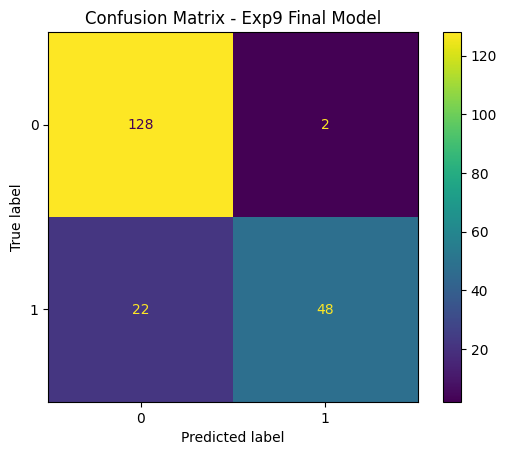

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import torch

model_exp9.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, sex_labels, bmi_labels in val_loader:
        images = images.to(device)
        sex_labels = sex_labels.to(device)

        sex_outputs, bmi_outputs = model_exp9(images)

        preds = torch.argmax(sex_outputs, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(sex_labels.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, zero_division=0)
recall = recall_score(all_labels, all_preds, zero_division=0)
f1 = f1_score(all_labels, all_preds, zero_division=0)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Exp9 Final Model")
plt.show()

In [ ]:
group_0_mask = all_labels == 0
group_1_mask = all_labels == 1

group_0_accuracy = accuracy_score(all_labels[group_0_mask], all_preds[group_0_mask])
group_1_accuracy = accuracy_score(all_labels[group_1_mask], all_preds[group_1_mask])

print("Sex Group 0 Accuracy:", group_0_accuracy)
print("Sex Group 1 Accuracy:", group_1_accuracy)

print("Number of Group 0 samples:", group_0_mask.sum())
print("Number of Group 1 samples:", group_1_mask.sum())

Sex Group 0 Accuracy: 0.9846153846153847
Sex Group 1 Accuracy: 0.6857142857142857
Number of Group 0 samples: 130
Number of Group 1 samples: 70


In [ ]:
model_exp9.eval()

highest_loss_images = []
highest_loss_labels = []
highest_loss_preds = []
highest_losses = []

loss_fn = torch.nn.CrossEntropyLoss(reduction="none")

with torch.no_grad():
    for images, sex_labels, bmi_labels in val_loader:
        images = images.to(device)
        sex_labels = sex_labels.to(device).long()

        sex_outputs, bmi_outputs = model_exp9(images)

        losses = loss_fn(sex_outputs, sex_labels)

        preds = torch.argmax(sex_outputs, dim=1)

        for i in range(images.size(0)):
            highest_loss_images.append(images[i].cpu())
            highest_loss_labels.append(sex_labels[i].cpu().item())
            highest_loss_preds.append(preds[i].cpu().item())
            highest_losses.append(losses[i].cpu().item())

highest_indices = np.argsort(highest_losses)[-5:][::-1]

print("Top 5 highest loss validation samples:")
for idx in highest_indices:
    print(
        "Loss:", highest_losses[idx],
        "True label:", highest_loss_labels[idx],
        "Predicted:", highest_loss_preds[idx]
    )

Top 5 highest loss validation samples:
Loss: 8.526464462280273 True label: 1 Predicted: 0
Loss: 8.37851619720459 True label: 1 Predicted: 0
Loss: 7.7991943359375 True label: 1 Predicted: 0
Loss: 7.554121494293213 True label: 1 Predicted: 0
Loss: 6.905172348022461 True label: 1 Predicted: 0


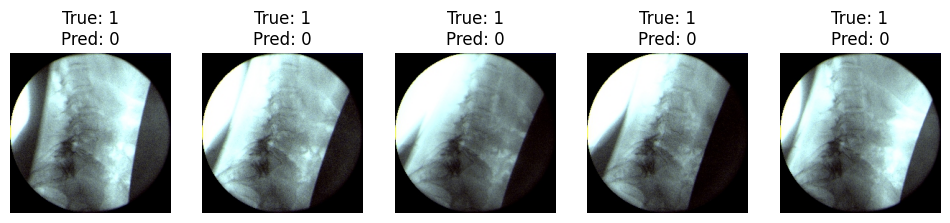

In [ ]:
import matplotlib.pyplot as plt

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(12, 6))

for plot_idx, idx in enumerate(highest_indices):
    image = highest_loss_images[idx]
    image = image * std + mean
    image = image.permute(1, 2, 0).numpy()
    image = np.clip(image, 0, 1)

    plt.subplot(1, 5, plot_idx + 1)
    plt.imshow(image)
    plt.title(
        f"True: {int(highest_loss_labels[idx])}\nPred: {int(highest_loss_preds[idx])}"
    )
    plt.axis("off")

plt.show()

In [ ]:
!pip install grad-cam

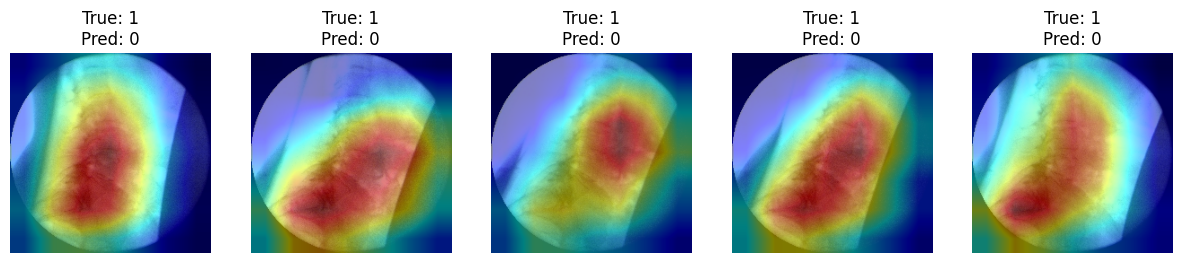

In [ ]:
import torch
import torch.nn as nn
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt
import numpy as np

class SexOnlyModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        sex_outputs, bmi_outputs = self.model(x)
        return sex_outputs

sex_model_exp9 = SexOnlyModel(model_exp9)
sex_model_exp9.eval()

target_layers = [model_exp9.backbone.layer4[-1]]

cam = GradCAM(
    model=sex_model_exp9,
    target_layers=target_layers
)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

plt.figure(figsize=(15, 8))

for i, idx in enumerate(highest_indices):
    image = highest_loss_images[idx]
    input_tensor = image.unsqueeze(0).to(device)

    grayscale_cam = cam(input_tensor=input_tensor)[0]

    img = image * std + mean
    img = img.permute(1, 2, 0).numpy()
    img = np.clip(img, 0, 1)

    visualization = show_cam_on_image(
        img.astype(np.float32),
        grayscale_cam,
        use_rgb=True
    )

    plt.subplot(1, 5, i + 1)
    plt.imshow(visualization)
    plt.title(
        f"True: {int(highest_loss_labels[idx])}\nPred: {int(highest_loss_preds[idx])}"
    )
    plt.axis("off")

plt.show()

## 6. Final Model Evaluation and Explainability (XAI)

Based on the experiment results, Exp9 (ResNet18 + AdamW) was selected because it achieved the highest validation accuracy (0.895), stable convergence behaviour, and lower overfitting compared with other experiments. The model achieved a validation accuracy of 0.88 and also produced good BMI prediction results compared with other experiments.

To better understand model performance, additional evaluation methods were applied. The model achieved an accuracy of 0.88, a precision score of 0.96, a recall score of 0.68, and an F1-score of 0.80. The high precision value shows that most positive predictions made by the model were correct. However, the lower recall value shows that some positive samples were still missed.

The confusion matrix gives more information about prediction results. The model correctly classified 128 negative samples and 48 positive samples. Only 2 negative samples were incorrectly classified as positive. However, 22 positive samples were predicted as negative. This suggests that the model was more careful when predicting positive cases, but it sometimes missed real positive samples.

Model performance was also evaluated across sex groups. Group 0 achieved an accuracy of 0.985 while Group 1 achieved an accuracy of 0.686. This difference may suggest possible bias in the dataset or differences in the learning process. Medical prediction systems should provide fair results for different groups, so this issue should be considered.

For explainability, Grad-CAM was applied to validation images with the highest prediction loss. The visualisations showed that the model mainly focused on central anatomical regions in the X-ray images. The model generally focused on meaningful image areas instead of background regions. However, the selected examples were still incorrectly classified, which suggests that some difficult patterns were not fully learned.

Beyond accuracy, model reliability should also be considered. Although the model achieved good performance on the validation dataset, some limitations still exist. The dataset size is relatively small and the model may perform differently on unseen images. Additional testing and validation would be needed before using the model in real medical situations.

### Reliability Discussion

Although the model achieved high overall accuracy, reliability should not be evaluated using accuracy alone. The model showed noticeable differences across sex groups, suggesting potential fairness issues. In addition, the lower recall score indicates that some cases were still missed. Since the dataset is relatively small, the model may not generalise well to unseen medical images collected from different populations or imaging conditions.

## 7. Conclusion and Reflection

The aim of this project was to develop a computer vision system that can predict sex and BMI from X-ray images. A baseline CNN model was first created and then different experiments were performed to improve model performance. Several methods were tested, including data augmentation, dropout, different optimisation methods, deeper architectures, and pretrained models.

The results showed that pretrained models performed better than the baseline CNN model. Among all experiments, Exp9 (ResNet18 + AdamW) achieved the best overall performance. The final model reached an accuracy of 0.88 with good BMI prediction performance. Additional evaluation methods such as confusion matrix, precision, recall, F1-score, fairness analysis, and Grad-CAM were also used to better understand model behaviour and performance.

Although the model achieved good results, I would not recommend immediate use of this system in real medical environments. Medical systems need very high reliability because incorrect predictions may affect real decisions. The fairness analysis also showed performance differences between groups, which may indicate possible bias.

Before using this model in real-world situations, additional safeguards and testing would be required. These include testing on larger datasets, using new unseen patient data, improving fairness between groups, and performing more validation studies. Expert review from medical professionals would also be important before practical use. At the current stage, the model should be considered a proof-of-concept system rather than a fully deployable medical tool.